In [ ]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Đường dẫn gốc dự án
PROJECT_ROOT = '/content/drive/MyDrive/flower-multilabel-project'

import os

# 3. Kiểm tra dữ liệu Tuần 2 vẫn còn nguyên
splits_dir = os.path.join(PROJECT_ROOT, 'data/splits')
for split in ['train', 'val', 'test']:
    split_path = os.path.join(splits_dir, split)
    if os.path.exists(split_path):
        n_files = len([f for f in os.listdir(split_path) if f.endswith('.jpg')])
        print(f"✅ {split}: {n_files} ảnh")
    else:
        print(f"❌ KHÔNG TÌM THẤY: {split_path}")

# 4. Kiểm tra classes.json
classes_path = os.path.join(PROJECT_ROOT, 'data/metadata/classes.json')
import json
with open(classes_path, 'r', encoding='utf-8') as f:
    classes_data = json.load(f)
print("\n✅ classes.json:", classes_data)

# 5. Tạo thư mục mới cho Tuần 3 (checkpoints theo từng kiến trúc + comparison)
model_names = ['mobilenetv2', 'mobilenetv3large', 'efficientnetb0', 'resnet50v2', 'densenet121']

for name in model_names:
    ckpt_dir = os.path.join(PROJECT_ROOT, 'models/checkpoints', name)
    os.makedirs(ckpt_dir, exist_ok=True)
    print(f"📁 Đã tạo: {ckpt_dir}")

comparison_dir = os.path.join(PROJECT_ROOT, 'models/comparison')
os.makedirs(comparison_dir, exist_ok=True)
print(f"📁 Đã tạo: {comparison_dir}")

final_dir = os.path.join(PROJECT_ROOT, 'models/final')
os.makedirs(final_dir, exist_ok=True)
print(f"📁 Đã tạo (nếu chưa có): {final_dir}")

# 6. Kiểm tra phiên bản TensorFlow
import tensorflow as tf
print(f"\n✅ TensorFlow version: {tf.__version__}")
print(f"✅ GPU available: {tf.config.list_physical_devices('GPU')}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ train: 4200 ảnh
✅ val: 900 ảnh
✅ test: 900 ảnh

✅ classes.json: [{'index': 0, 'id': 'hoa_hong', 'name': 'Hoa Hồng'}, {'index': 1, 'id': 'hoa_huong_duong', 'name': 'Hoa Hướng Dương'}, {'index': 2, 'id': 'hoa_cuc', 'name': 'Hoa Cúc'}, {'index': 3, 'id': 'hoa_tulip', 'name': 'Hoa Tulip'}, {'index': 4, 'id': 'hoa_bo_cong_anh', 'name': 'Bồ Công Anh'}, {'index': 5, 'id': 'hoa_sen', 'name': 'Hoa Sen'}, {'index': 6, 'id': 'hoa_lan', 'name': 'Hoa Lan'}, {'index': 7, 'id': 'hoa_mai', 'name': 'Hoa Mai'}, {'index': 8, 'id': 'hoa_dao', 'name': 'Hoa Đào'}, {'index': 9, 'id': 'hoa_oai_huong', 'name': 'Oải Hương'}]
📁 Đã tạo: /content/drive/MyDrive/flower-multilabel-project/models/checkpoints/mobilenetv2
📁 Đã tạo: /content/drive/MyDrive/flower-multilabel-project/models/checkpoints/mobilenetv3large
📁 Đã tạo: /content/drive/MyDrive/flower-multilabel-project/models/checkpoints

In [ ]:
# XÂY DỰNG DATA PIPELINE

import pandas as pd
import numpy as np
import tensorflow as tf

# 1. Đọc file nhãn ĐẦY ĐỦ (6000 dòng: composite + augmented)
labels_csv_path = os.path.join(PROJECT_ROOT, 'data/metadata/full_labels.csv')
labels_df = pd.read_csv(labels_csv_path)
print("Số dòng trong full_labels.csv:", len(labels_df))
print(labels_df.head())

# 2. Lấy đúng thứ tự 10 class từ classes.json (KHÔNG được lệch thứ tự)
class_ids = [c['id'] for c in classes_data]
print("\nThứ tự 10 class (cố định):", class_ids)

IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# 3. Hàm helper: lọc dòng trong labels_df khớp với ảnh thực có trong thư mục split
def build_split_dataframe(split_name):
    split_dir = os.path.join(splits_dir, split_name)
    files_in_split = set(os.listdir(split_dir))
    df_split = labels_df[labels_df['filename'].isin(files_in_split)].copy()
    df_split['filepath'] = df_split['filename'].apply(lambda f: os.path.join(split_dir, f))
    return df_split.reset_index(drop=True)

train_df = build_split_dataframe('train')
val_df   = build_split_dataframe('val')
test_df  = build_split_dataframe('test')

print(f"\nTrain: {len(train_df)} dòng khớp nhãn  (mong đợi ~4200)")
print(f"Val:   {len(val_df)} dòng khớp nhãn  (mong đợi ~900)")
print(f"Test:  {len(test_df)} dòng khớp nhãn  (mong đợi ~900)")

# 4. Hàm load + preprocess 1 ảnh
def load_image(filepath, label):
    img = tf.io.read_file(filepath)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32)   # KHÔNG chia /255.0 nữa — để nguyên [0,255]
    return img, label

# 5. Hàm tạo tf.data.Dataset từ 1 dataframe
def make_dataset(df, shuffle=False, batch_size=BATCH_SIZE):
    filepaths = df['filepath'].values
    labels = df[class_ids].values.astype('float32')

    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(df), reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(batch_size)
    ds = ds.prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, shuffle=True)
val_ds   = make_dataset(val_df, shuffle=False)
test_ds  = make_dataset(test_df, shuffle=False)

# 6. Kiểm tra nhanh
for imgs, lbls in train_ds.take(1):
    print("\n✅ Batch ảnh shape:", imgs.shape)
    print("✅ Batch nhãn shape:", lbls.shape)
    print("✅ Ví dụ 1 nhãn multi-hot:", lbls[0].numpy())

Số dòng trong full_labels.csv: 6000
              filename  hoa_hong  hoa_huong_duong  hoa_cuc  hoa_tulip  \
0  composite_00000.jpg         0                1        0          0   
1  composite_00001.jpg         0                0        0          0   
2  composite_00002.jpg         0                0        0          0   
3  composite_00003.jpg         0                0        0          1   
4  composite_00004.jpg         0                0        1          0   

   hoa_bo_cong_anh  hoa_sen  hoa_lan  hoa_mai  hoa_dao  hoa_oai_huong  \
0                0        0        0        0        0              0   
1                0        0        0        0        1              0   
2                0        0        0        0        1              0   
3                0        0        1        0        1              0   
4                0        0        0        0        0              0   

         source_dir  
0  composite/images  
1  composite/images  
2  composite/images 

In [ ]:
# HÀM BUILD MODEL TỔNG QUÁT

from tensorflow.keras.applications import (
    MobileNetV2, MobileNetV3Large, EfficientNetB0, ResNet50V2, DenseNet121
)
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as pp_mobilenetv2
from tensorflow.keras.applications.mobilenet_v3 import preprocess_input as pp_mobilenetv3large
from tensorflow.keras.applications.efficientnet import preprocess_input as pp_efficientnetb0
from tensorflow.keras.applications.resnet_v2 import preprocess_input as pp_resnet50v2
from tensorflow.keras.applications.densenet import preprocess_input as pp_densenet121

from tensorflow.keras import layers, models, optimizers

NUM_CLASSES = len(class_ids)  # = 10

# 1. Bảng cấu hình 5 kiến trúc: base model class + hàm preprocess riêng của nó
MODEL_REGISTRY = {
    'mobilenetv2':     {'base_class': MobileNetV2,      'preprocess': pp_mobilenetv2},
    'mobilenetv3large':{'base_class': MobileNetV3Large,  'preprocess': pp_mobilenetv3large},
    'efficientnetb0':  {'base_class': EfficientNetB0,    'preprocess': pp_efficientnetb0},
    'resnet50v2':      {'base_class': ResNet50V2,        'preprocess': pp_resnet50v2},
    'densenet121':     {'base_class': DenseNet121,       'preprocess': pp_densenet121},
}

# 2. Hàm build model: nhận tên kiến trúc, trả về (model, base_model_layer)
#    base_model_layer trả riêng ra để sau này dễ dùng khi fine-tuning (mở khóa 1 số lớp cuối)
def build_model(model_name):
    config = MODEL_REGISTRY[model_name]
    base_class = config['base_class']

    # Base model, đóng băng ban đầu (feature extraction)
    base_model = base_class(
        include_top=False,
        weights='imagenet',
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    base_model.trainable = False  # đóng băng — giai đoạn 1

    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = config['preprocess'](inputs)          # mỗi model tự chuẩn hóa theo đúng chuẩn của nó
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='sigmoid')(x)

    model = models.Model(inputs, outputs, name=model_name)
    return model, base_model

# 3. Test thử build 1 model để chắc chắn hàm chạy đúng (chưa train)
test_model, test_base = build_model('mobilenetv2')
test_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['AUC']
)
test_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,588,490 (9.87 MB)

 Trainable params: 330,506 (1.26 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
# TRAIN GIAI ĐOẠN 1 (FEATURE EXTRACTION)

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import time
import json

EPOCHS_STAGE1 = 20   # epoch tối đa — EarlyStopping sẽ tự dừng sớm nếu hội tụ trước
PATIENCE = 4

# Dict lưu lại model đã build + history để dùng tiếp ở Cell 5 (fine-tuning)
trained_models = {}       # {model_name: keras.Model}
base_models_ref = {}      # {model_name: base_model layer, để fine-tune sau}
stage1_history = {}       # {model_name: history dict}

for model_name in MODEL_REGISTRY.keys():
    print(f"\n{'='*60}")
    print(f"🚀 GIAI ĐOẠN 1 — {model_name}")
    print(f"{'='*60}")

    start_time = time.time()

    model, base_model = build_model(model_name)
    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-4),
        loss='binary_crossentropy',
        metrics=['AUC', 'Precision', 'Recall']
    )

    ckpt_path = os.path.join(PROJECT_ROOT, 'models/checkpoints', model_name, 'stage1_best.keras')

    callbacks = [
        EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True),
        ModelCheckpoint(ckpt_path, monitor='val_loss', save_best_only=True)
    ]

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS_STAGE1,
        callbacks=callbacks,
        verbose=1
    )

    elapsed = time.time() - start_time
    print(f"⏱️ {model_name} — Giai đoạn 1 xong trong {elapsed/60:.1f} phút, "
          f"dừng ở epoch {len(history.history['loss'])}")

    trained_models[model_name] = model
    base_models_ref[model_name] = base_model
    stage1_history[model_name] = history.history

    # Lưu history ra file luôn, phòng khi Colab bị ngắt giữa chừng
    history_path = os.path.join(PROJECT_ROOT, 'models/checkpoints', model_name, 'stage1_history.json')
    with open(history_path, 'w') as f:
        json.dump(history.history, f)

print("\n✅ Hoàn tất Giai đoạn 1 cho cả 5 model!")


🚀 GIAI ĐOẠN 1 — mobilenetv2
Epoch 1/20
132/132 ━━━━━━━━━━━━━━━━━━━━ 2284s 17s/step - AUC: 0.6526 - Precision: 0.4196 - Recall: 0.1858 - loss: 0.4974 - val_AUC: 0.8057 - val_Precision: 0.8119 - val_Recall: 0.2252 - val_loss: 0.3967
Epoch 2/20
132/132 ━━━━━━━━━━━━━━━━━━━━ 9s 69ms/step - AUC: 0.8170 - Precision: 0.7179 - Recall: 0.3655 - loss: 0.3822 - val_AUC: 0.8652 - val_Precision: 0.8322 - val_Recall: 0.4003 - val_loss: 0.3419
Epoch 3/20
132/132 ━━━━━━━━━━━━━━━━━━━━ 12s 82ms/step - AUC: 0.8653 - Precision: 0.7618 - Recall: 0.4657 - loss: 0.3367 - val_AUC: 0.8868 - val_Precision: 0.8400 - val_Recall: 0.4728 - val_loss: 0.3149
Epoch 4/20
132/132 ━━━━━━━━━━━━━━━━━━━━ 11s 87ms/step - AUC: 0.8888 - Precision: 0.7843 - Recall: 0.5159 - loss: 0.3105 - val_AUC: 0.9027 - val_Precision: 0.8523 - val_Recall: 0.5102 - val_loss: 0.2950
Epoch 5/20
132/132 ━━━━━━━━━━━━━━━━━━━━ 20s 82ms/step - AUC: 0.9048 - Precision: 0.7980 - Recall: 0.5506 - loss: 0.2905 - val_AUC: 0.9110 - val_Precision: 0.8566 -

In [ ]:
# TRAIN GIAI ĐOẠN 2 (FINE-TUNING)

EPOCHS_STAGE2 = 15
PATIENCE_STAGE2 = 3
FINE_TUNE_FRACTION = 0.3   # mở khóa 30% lớp cuối của base model (tỷ lệ, không phải số cố định
                            # vì mỗi kiến trúc có tổng số lớp khác nhau)

stage2_history = {}

for model_name in MODEL_REGISTRY.keys():
    print(f"\n{'='*60}")
    print(f"🔧 GIAI ĐOẠN 2 (FINE-TUNING) — {model_name}")
    print(f"{'='*60}")

    start_time = time.time()

    model = trained_models[model_name]
    base_model = base_models_ref[model_name]

    # Mở khóa base model, nhưng chỉ phần cuối
    base_model.trainable = True
    n_layers = len(base_model.layers)
    freeze_until = int(n_layers * (1 - FINE_TUNE_FRACTION))

    for layer in base_model.layers[:freeze_until]:
        layer.trainable = False
    for layer in base_model.layers[freeze_until:]:
        layer.trainable = True

    print(f"Tổng số lớp base: {n_layers}, mở khóa từ lớp {freeze_until} trở đi "
          f"({n_layers - freeze_until} lớp được train)")

    # Recompile BẮT BUỘC sau khi đổi trainable, learning rate thấp hơn hẳn
    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-5),
        loss='binary_crossentropy',
        metrics=['AUC', 'Precision', 'Recall']
    )

    ckpt_path = os.path.join(PROJECT_ROOT, 'models/checkpoints', model_name, 'stage2_best.keras')

    callbacks = [
        EarlyStopping(monitor='val_loss', patience=PATIENCE_STAGE2, restore_best_weights=True),
        ModelCheckpoint(ckpt_path, monitor='val_loss', save_best_only=True)
    ]

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS_STAGE2,
        callbacks=callbacks,
        verbose=1
    )

    elapsed = time.time() - start_time
    print(f"⏱️ {model_name} — Giai đoạn 2 xong trong {elapsed/60:.1f} phút, "
          f"dừng ở epoch {len(history.history['loss'])}")

    trained_models[model_name] = model  # đã fine-tune, ghi đè lại
    stage2_history[model_name] = history.history

    history_path = os.path.join(PROJECT_ROOT, 'models/checkpoints', model_name, 'stage2_history.json')
    with open(history_path, 'w') as f:
        json.dump(history.history, f)

print("\n✅ Hoàn tất Giai đoạn 2 (fine-tuning) cho cả 5 model!")


🔧 GIAI ĐOẠN 2 (FINE-TUNING) — mobilenetv2
Tổng số lớp base: 154, mở khóa từ lớp 107 trở đi (47 lớp được train)
Epoch 1/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 55s 244ms/step - AUC: 0.8939 - Precision: 0.8060 - Recall: 0.5121 - loss: 0.3029 - val_AUC: 0.9496 - val_Precision: 0.8570 - val_Recall: 0.6914 - val_loss: 0.2117
Epoch 2/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 11s 85ms/step - AUC: 0.9388 - Precision: 0.8483 - Recall: 0.6507 - loss: 0.2377 - val_AUC: 0.9526 - val_Precision: 0.8641 - val_Recall: 0.7161 - val_loss: 0.2043
Epoch 3/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 20s 79ms/step - AUC: 0.9547 - Precision: 0.8733 - Recall: 0.7029 - loss: 0.2076 - val_AUC: 0.9564 - val_Precision: 0.8712 - val_Recall: 0.7320 - val_loss: 0.1958
Epoch 4/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 12s 88ms/step - AUC: 0.9647 - Precision: 0.8914 - Recall: 0.7408 - loss: 0.1859 - val_AUC: 0.9598 - val_Precision: 0.8747 - val_Recall: 0.7435 - val_loss: 0.1874
Epoch 5/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 13s 101ms/step - AUC: 0.9728 - Precisio

In [ ]:
# Đánh giá

import numpy as np

evaluation_results = {}

for model_name in MODEL_REGISTRY.keys():
    print(f"\n{'='*60}")
    print(f"📊 ĐÁNH GIÁ — {model_name}")
    print(f"{'='*60}")

    model = trained_models[model_name]

    # 1. Metric có sẵn từ compile (loss, auc, precision, recall)
    metrics_dict = model.evaluate(test_ds, verbose=0, return_dict=True)

    def find_metric(keyword, d=metrics_dict):
        for k, v in d.items():
            if keyword in k.lower():
                return v
        raise KeyError(f"Không tìm thấy metric chứa '{keyword}' trong {list(d.keys())}")

    loss_val = find_metric('loss')
    auc_val = find_metric('auc')
    precision_val = find_metric('precision')
    recall_val = find_metric('recall')

    # 2. Predict lại TOÀN BỘ tập test CHO ĐÚNG MODEL NÀY, để tính accuracy thủ công
    y_true_all = []
    y_pred_all = []
    for imgs, lbls in test_ds:
        preds = model.predict(imgs, verbose=0)
        y_true_all.append(lbls.numpy())
        y_pred_all.append(preds)

    y_true_all = np.concatenate(y_true_all, axis=0)
    y_pred_all = np.concatenate(y_pred_all, axis=0)
    y_pred_binary = (y_pred_all >= 0.5).astype(int)

    subset_accuracy = float(np.mean(np.all(y_pred_binary == y_true_all, axis=1)))
    hamming_accuracy = float(np.mean(y_pred_binary == y_true_all))

    evaluation_results[model_name] = {
        'test_loss': float(loss_val),
        'test_auc': float(auc_val),
        'test_precision': float(precision_val),
        'test_recall': float(recall_val),
        'test_subset_accuracy': subset_accuracy,
        'test_hamming_accuracy': hamming_accuracy,
        'stage1_epochs_run': len(stage1_history[model_name]['loss']),
        'stage2_epochs_run': len(stage2_history[model_name]['loss']),
    }

    print(f"  Loss: {loss_val:.4f} | AUC: {auc_val:.4f} | "
          f"Precision: {precision_val:.4f} | Recall: {recall_val:.4f}")
    print(f"  Subset accuracy: {subset_accuracy:.4f} | Hamming accuracy: {hamming_accuracy:.4f}")

# 3. Chọn model tốt nhất theo AUC
best_model_name = max(evaluation_results, key=lambda k: evaluation_results[k]['test_auc'])
print(f"\n🏆 MODEL TỐT NHẤT (theo test AUC): {best_model_name}")
print(f"   AUC = {evaluation_results[best_model_name]['test_auc']:.4f}")

display_names = {
    'mobilenetv2': 'MobileNetV2',
    'mobilenetv3large': 'MobileNetV3Large',
    'efficientnetb0': 'EfficientNetB0',
    'resnet50v2': 'ResNet50V2',
    'densenet121': 'DenseNet121',
}

comparison_output = {
    "models": [
        {
            "id": name,
            "name": display_names[name],
            "val_accuracy": evaluation_results[name]['test_hamming_accuracy'],
            "val_auc": evaluation_results[name]['test_auc'],
            "precision": evaluation_results[name]['test_precision'],
            "recall": evaluation_results[name]['test_recall'],
            "is_selected": (name == best_model_name)
        }
        for name in MODEL_REGISTRY.keys()
    ]
}

comparison_path = os.path.join(PROJECT_ROOT, 'models/comparison/model_comparison.json')
with open(comparison_path, 'w', encoding='utf-8') as f:
    json.dump(comparison_output, f, ensure_ascii=False, indent=2)
print(f"\n✅ Đã lưu: {comparison_path}")

final_model_path = os.path.join(PROJECT_ROOT, 'models/final/flower_multilabel_model.keras')
trained_models[best_model_name].save(final_model_path)
print(f"✅ Đã lưu model tốt nhất vào: {final_model_path}")


📊 ĐÁNH GIÁ — mobilenetv2
  Loss: 0.1350 | AUC: 0.9780 | Precision: 0.9206 | Recall: 0.8200
  Subset accuracy: 0.6211 | Hamming accuracy: 0.9496

📊 ĐÁNH GIÁ — mobilenetv3large
  Loss: 0.1248 | AUC: 0.9822 | Precision: 0.9350 | Recall: 0.8261
  Subset accuracy: 0.6511 | Hamming accuracy: 0.9534

📊 ĐÁNH GIÁ — efficientnetb0
  Loss: 0.1125 | AUC: 0.9871 | Precision: 0.9465 | Recall: 0.8305
  Subset accuracy: 0.6500 | Hamming accuracy: 0.9564

📊 ĐÁNH GIÁ — resnet50v2
  Loss: 0.1317 | AUC: 0.9796 | Precision: 0.9441 | Recall: 0.8200
  Subset accuracy: 0.6500 | Hamming accuracy: 0.9540

📊 ĐÁNH GIÁ — densenet121
  Loss: 0.1056 | AUC: 0.9889 | Precision: 0.9468 | Recall: 0.8454
  Subset accuracy: 0.6856 | Hamming accuracy: 0.9593

🏆 MODEL TỐT NHẤT (theo test AUC): densenet121
   AUC = 0.9889

✅ Đã lưu: /content/drive/MyDrive/flower-multilabel-project/models/comparison/model_comparison.json
✅ Đã lưu model tốt nhất vào: /content/drive/MyDrive/flower-multilabel-project/models/final/flower_multila

In [ ]:
# HIỂN THỊ BẢNG SO SÁNH ĐẦY ĐỦ 5 MODEL

import pandas as pd

summary_rows = []
for name in MODEL_REGISTRY.keys():
    r = evaluation_results[name]
    summary_rows.append({
        'Model': display_names[name],
        'Test AUC': round(r['test_auc'], 4),
        'Test Precision': round(r['test_precision'], 4),
        'Test Recall': round(r['test_recall'], 4),
        'Hamming Acc': round(r['test_hamming_accuracy'], 4),
        'Subset Acc': round(r['test_subset_accuracy'], 4),
        'Epochs (S1+S2)': f"{r['stage1_epochs_run']}+{r['stage2_epochs_run']}",
        'Chọn': '🏆' if name == best_model_name else ''
    })

summary_df = pd.DataFrame(summary_rows).sort_values('Test AUC', ascending=False).reset_index(drop=True)
print(summary_df.to_string(index=False))

           Model  Test AUC  Test Precision  Test Recall  Hamming Acc  Subset Acc Epochs (S1+S2) Chọn
     DenseNet121    0.9889          0.9468       0.8454       0.9593      0.6856          20+15    🏆
  EfficientNetB0    0.9871          0.9465       0.8305       0.9564      0.6500          20+15     
MobileNetV3Large    0.9822          0.9350       0.8261       0.9534      0.6511          20+15     
      ResNet50V2    0.9796          0.9441       0.8200       0.9540      0.6500          20+15     
     MobileNetV2    0.9780          0.9206       0.8200       0.9496      0.6211          20+15     


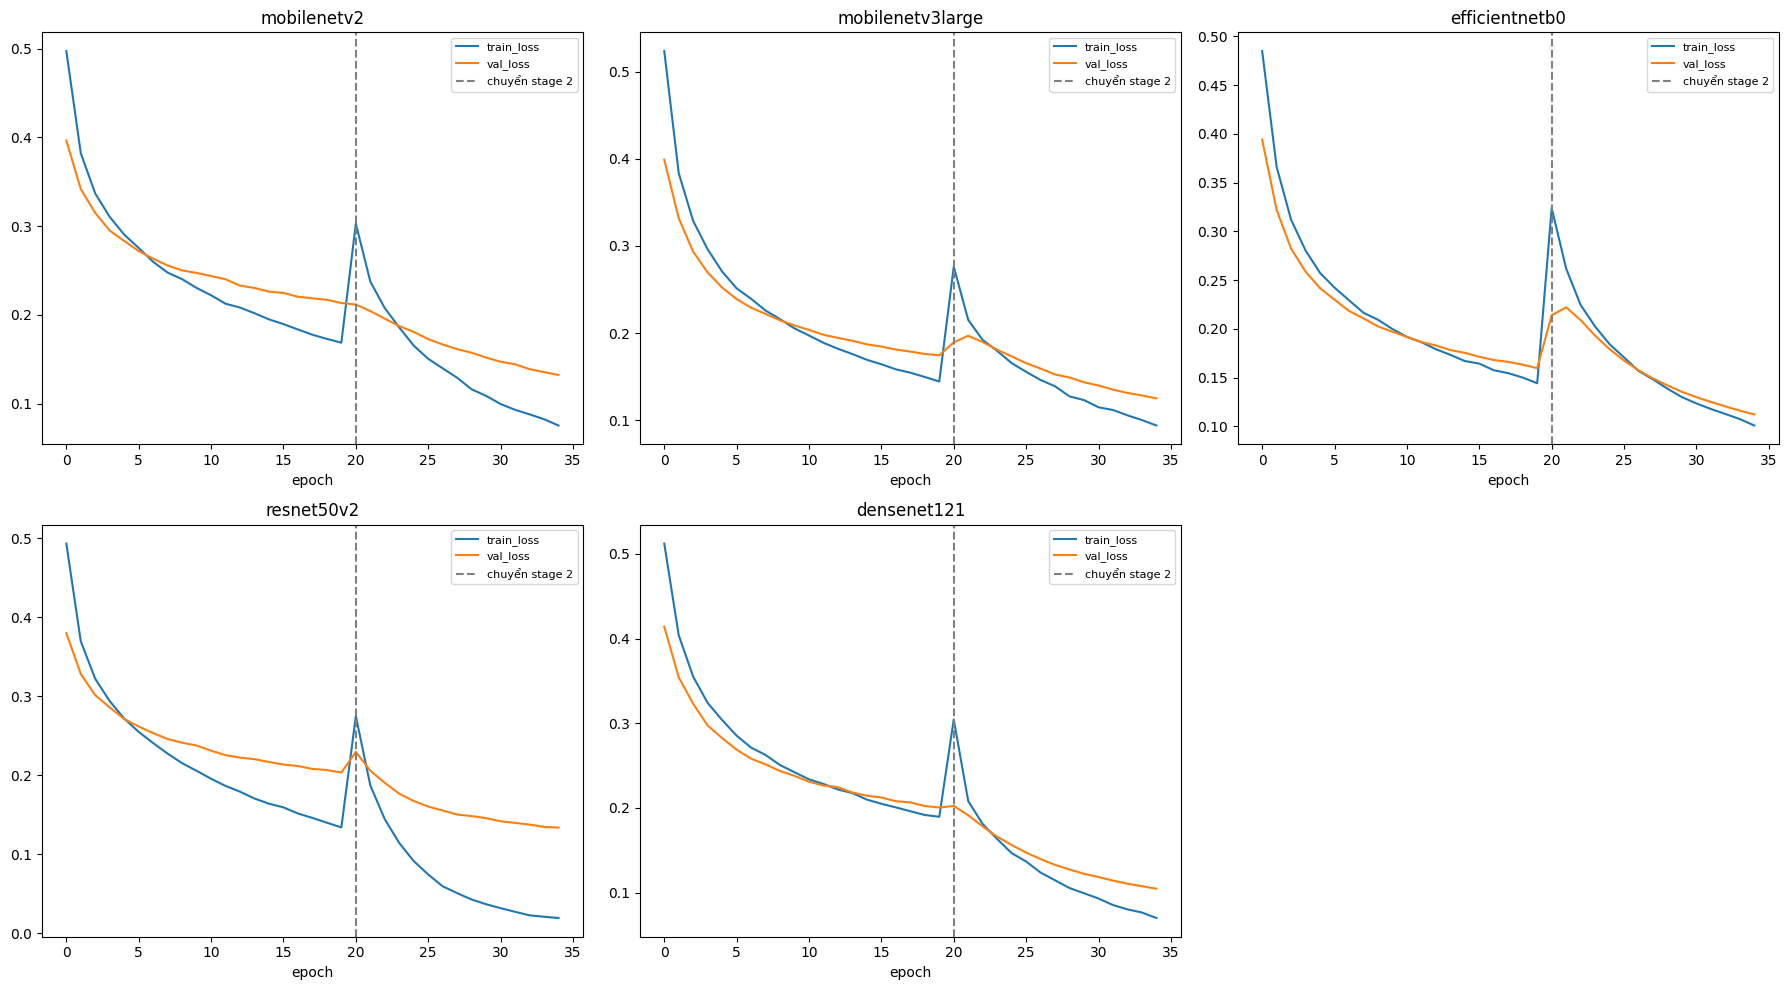

In [ ]:
# VẼ LOSS CURVE CỦA CẢ 5 MODEL (STAGE1 + STAGE2 NỐI TIẾP)

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, model_name in enumerate(MODEL_REGISTRY.keys()):
    s1 = stage1_history[model_name]
    s2 = stage2_history[model_name]

    train_loss = s1['loss'] + s2['loss']
    val_loss = s1['val_loss'] + s2['val_loss']
    stage_boundary = len(s1['loss'])  # epoch nào chuyển sang stage 2

    ax = axes[i]
    ax.plot(train_loss, label='train_loss')
    ax.plot(val_loss, label='val_loss')
    ax.axvline(stage_boundary, color='gray', linestyle='--', label='chuyển stage 2')
    ax.set_title(model_name)
    ax.set_xlabel('epoch')
    ax.legend(fontsize=8)

axes[-1].axis('off')  # ô thừa (5 model / 6 ô)
plt.tight_layout()
plt.savefig(os.path.join(PROJECT_ROOT, 'reports/weekly_progress/tuan3_loss_curves.png'), dpi=120)
plt.show()